# 02 · Zentrierte Embeddings: wird die Triage besser?

**Frage:** Unser Embedding-Modell (e5) hält alle Urteile für fast gleich ähnlich. Hilft es, vorher den
**Durchschnittsvektor abzuziehen** („Zentrieren“)? Gemessen mit **denselben Regeln wie Abis Evaluation** (`results/eval.md`, Issue #21).

**Aufbau**
1. Das Problem in einer Zahl
2. Die Idee: Durchschnitt abziehen
3. Fairer Vergleich: gleiche Regeln wie Abi
4. Ergebnis: Rangliste und Schwellen
5. Passen die ähnlichen Referenzfälle besser?
6. Was ein Boost- oder Buff-Klick bewirkt
7. Fazit und Empfehlung

Rechenlogik: `src/hack_apertus_coffee_exe/eval/relevance.py` (Tests: `tests/test_eval_relevance.py`). Kein Modellaufruf, nur gespeicherte Vektoren.


In [1]:
import os
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hack_apertus_coffee_exe.eval.eval import score_vectordb
from hack_apertus_coffee_exe.eval.relevance import (
    Corpus, open_vectordb, pair_similarity, recall_curve, score_period, subject_area, summary_row, to_scored_cases,
)
from hack_apertus_coffee_exe.triage.date_filter import DateRange

pd.set_option("display.precision", 3)
BLUE, ORANGE, GRAY, INK = "#257de0", "#f47230", "#9c9c9c", "#191919"

db = open_vectordb()
corpus = Corpus(db)   # alle 6053 Urteile mit Vektoren, einmal geladen

# Abis Setup: Kandidaten Q1/2026, Referenzen nur die Suva-Fälle aus Q4/2025
Q1 = dict(date_from="2026-01-01", date_to="2026-03-31", ref_date_from="2025-10-01", ref_date_to="2025-12-31")
Q4 = dict(date_from="2025-10-01", date_to="2025-12-31", ref_date_from="2025-07-01", ref_date_to="2025-09-30")

## 1. Das Problem in einer Zahl

Wir vergleichen zufällige Paare von Urteilen aus Q1/2026. 1.0 = identisch.
Ein gutes Modell sollte zwei Unfall-Urteile deutlich ähnlicher finden als ein Unfall-Urteil und ein Strafurteil.


In [2]:
m = corpus.meta[(corpus.meta.decision_date >= "2026-01-01") & (corpus.meta.decision_date <= "2026-03-31")]
unfall = m[m.case_id.str.startswith("8C_") & m.subject.str.contains("Unfall|accident|infortun", case=False)].index.tolist()
fremd = m[m.case_id.str[:2].isin(["1C", "2C", "5A", "6B", "7B"])].index.tolist()   # Bau-, Ausländer-, Zivil-, Strafrecht

pairs = pd.DataFrame(
    {variant: {"Unfall ↔ Unfall": pair_similarity(corpus, unfall, unfall, centre=c, date_to="2026-03-31"),
               "Unfall ↔ fachfremd": pair_similarity(corpus, unfall, fremd, centre=c, date_to="2026-03-31")}
     for variant, c in [("heute (roh)", False), ("zentriert", True)]})
pairs.loc["Abstand"] = pairs.iloc[0] - pairs.iloc[1]
pairs

,heute (roh),zentriert
Unfall ↔ Unfall,0.944,0.259
Unfall ↔ fachfremd,0.921,-0.020
Abstand,0.023,0.280


**Heute:** Ein Unfall-Urteil ist einem anderen Unfall-Urteil nur um etwa 0.02 ähnlicher als einem Strafurteil.
Alle Bundesgerichtsurteile teilen Aufbau und Juristensprache, und e5 legt alle Vektoren in einen engen Kegel.
Deshalb liegen alle Scores zwischen 75 und 95, und **der Score unterscheidet vor allem über den fest eingebauten Bonus** (Kammer 8C, Unfall im Sachgebiet, UVG im Text).


## 2. Die Idee: Durchschnitt abziehen

Jeder Textabschnitt ist ein Pfeil mit 384 Zahlen. Alle Pfeile zeigen grob in dieselbe Richtung, das ist das Gemeinsame aller Urteile.
Ziehen wir den **Durchschnittspfeil** aller Urteile ab, bleibt nur übrig, **worin sich ein Urteil von den anderen unterscheidet**.

- Kein neues Modell, kein neues Embedding: eine Subtraktion auf den gespeicherten Vektoren, auch air-gapped.
- Der Durchschnitt wird nur aus Urteilen bis zum Ende des bewerteten Zeitraums gebildet und braucht **keine Suva-Labels**, es gibt also kein Leakage.

Wirkung auf die reine Ähnlichkeit (ohne Bonus), Q1/2026:


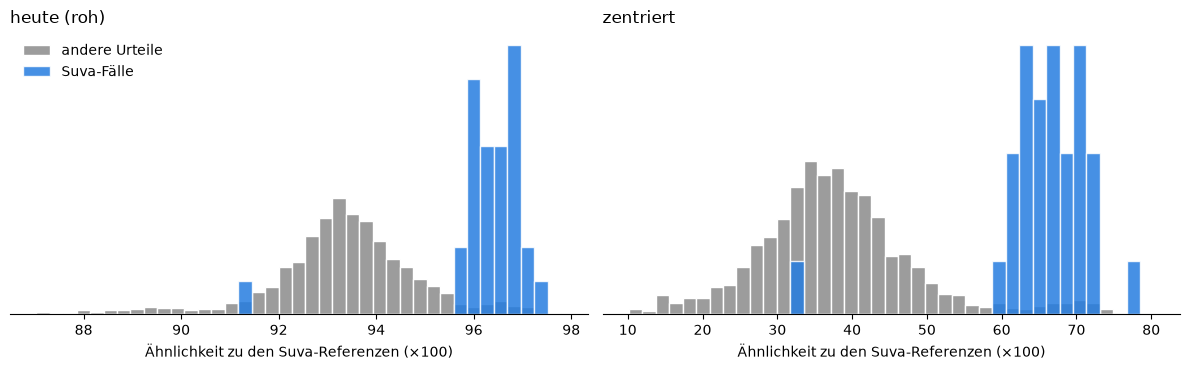

,heute (roh),zentriert
Mittel Suva,96.29,65.72
Mittel andere,93.32,37.98
Spannweite andere (min–max),10.77,70.20
Trennschärfe d',2.27,2.99


In [3]:
raw_sim = score_period(corpus, centre=False, bonus_scale=0, **Q1)
cen_sim = score_period(corpus, centre=True, bonus_scale=0, **Q1)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, frame, title in [(axes[0], raw_sim, "heute (roh)"), (axes[1], cen_sim, "zentriert")]:
    bins = np.linspace(frame.score.min(), frame.score.max(), 40)
    ax.hist(frame.loc[~frame.is_reference, "score"], bins=bins, density=True, color=GRAY, label="andere Urteile",
            edgecolor="white", linewidth=1)
    ax.hist(frame.loc[frame.is_reference, "score"], bins=bins, density=True, color=BLUE, alpha=0.85,
            label="Suva-Fälle", edgecolor="white", linewidth=1)
    ax.set_title(title, loc="left")
    ax.set_xlabel("Ähnlichkeit zu den Suva-Referenzen (×100)")
    ax.set_yticks([])
    ax.spines[["top", "right", "left"]].set_visible(False)
axes[0].legend(frameon=False, loc="upper left")
fig.tight_layout()
plt.show()

def separation(frame):
    s, o = frame[frame.is_reference].score, frame[~frame.is_reference].score
    return pd.Series({"Mittel Suva": s.mean(), "Mittel andere": o.mean(), "Spannweite andere (min–max)": o.max() - o.min(),
                      "Trennschärfe d'": (s.mean() - o.mean()) / np.sqrt((s.var() + o.var()) / 2)})

pd.DataFrame({"heute (roh)": separation(raw_sim), "zentriert": separation(cen_sim)}).round(2)

**Lesart:** Zentriert verteilen sich die Scores über einen viel grösseren Bereich, und die Suva-Fälle heben sich deutlicher ab.
d' misst, wie weit die beiden Gruppen auseinanderliegen, gemessen an ihrer Streuung. Höher ist besser.

**Achtung, die Grafik täuscht:** Sie zeigt Anteile. Grau sind 1973 Urteile, blau nur 31. Ein kaum sichtbarer grauer Ausläufer
im blauen Bereich sind trotzdem über 100 Urteile, vor allem Unfall-Urteile, die Suva *nicht* zusammengefasst hat.
Ob die Rangliste besser wird, zeigt erst Abschnitt 4.


## 3. Fairer Vergleich: gleiche Regeln wie Abi

`score_period` bildet Abis Formel aus `VectorDB.score_candidates` nach (Ähnlichkeit zu den 3 nächsten Referenzen + Fachgebiets-Bonus).
Einziger Unterschied: optional zentriert. **Kontrolle:** Ohne Zentrieren muss exakt Abis Ergebnis herauskommen.


In [4]:
abi = score_vectordb(db, DateRange.from_period("2026-Q1"), DateRange.from_period("2025-Q4"))
nachbau = score_period(corpus, centre=False, **Q1)
pd.DataFrame([summary_row("Abi (results/eval.md)", abi), summary_row("Nachbau ohne Zentrieren", to_scored_cases(nachbau))]
             ).set_index("Variante")[["F2", "Recall (bestes F2)", "Recall@30"]]

,F2,Recall (bestes F2),Recall@30
Variante,,,
Abi (results/eval.md),0.661,0.742,0.484
Nachbau ohne Zentrieren,0.661,0.742,0.484


Identisch, der Nachbau misst also dasselbe wie Abis Evaluation.

**Wie stark soll der Bonus zählen?** Nach dem Zentrieren hat die Ähnlichkeit eine andere Skala, der alte Bonus ist relativ kleiner.
Damit wir nicht auf den Testdaten schummeln, wählen wir den Bonus-Faktor auf **Q4/2025** (Referenzen Q3/2025) und testen danach auf Q1/2026.


In [5]:
tuning = pd.DataFrame([
    {"Bonus-Faktor": b, **summary_row("", to_scored_cases(score_period(corpus, centre=True, bonus_scale=b, **Q4)))}
    for b in (0, 0.5, 1, 1.5, 2, 3, 4)
]).set_index("Bonus-Faktor")[["F2", "Recall@30", "Recall@100"]]
BONUS = float(tuning["F2"].idxmax())
print(f"Bester Bonus-Faktor auf Q4/2025: {BONUS}  (Abis Formel entspricht 1.0)")
tuning

Bester Bonus-Faktor auf Q4/2025: 2.0  (Abis Formel entspricht 1.0)


,F2,Recall@30,Recall@100
Bonus-Faktor,,,
0.0,0.547,0.286,0.786
0.5,0.628,0.429,0.929
1.0,0.686,0.571,0.893
1.5,0.699,0.679,0.893
2.0,0.714,0.714,0.893
3.0,0.693,0.679,0.893
4.0,0.693,0.679,0.893


## 4. Ergebnis auf Q1/2026: Rangliste und Schwellen

In [6]:
variants = {
    "A · Abi: Ähnlichkeit + Bonus (heute)": nachbau,
    "B · heute ohne Bonus": score_period(corpus, centre=False, bonus_scale=0, **Q1),
    "C · zentriert: nur Ähnlichkeit": cen_sim,
    "D · zentriert + Bonus wie heute": score_period(corpus, centre=True, bonus_scale=1, **Q1),
    f"E · zentriert + Bonus ×{BONUS:g} (auf Q4 gewählt)": score_period(corpus, centre=True, bonus_scale=BONUS, **Q1),
}
comparison = pd.DataFrame([summary_row(name, to_scored_cases(f)) for name, f in variants.items()]).set_index("Variante")
comparison.to_csv("results/tables/centred_vs_baseline_q1_2026.csv")
comparison

,F2,Recall (bestes F2),Precision (bestes F2),Ausgewählt (bestes F2),Recall@30,Recall@100,Ausgewählt für 90 % Recall,Ausgewählt für 100 % Recall
Variante,,,,,,,,
A · Abi: Ähnlichkeit + Bonus (heute),0.661,0.742,0.460,50,0.484,0.839,114,1847
B · heute ohne Bonus,0.588,0.968,0.229,131,0.226,0.677,120,1840
C · zentriert: nur Ähnlichkeit,0.592,0.935,0.240,121,0.161,0.677,116,1401
D · zentriert + Bonus wie heute,0.650,0.839,0.342,76,0.387,0.871,114,1404
E · zentriert + Bonus ×2 (auf Q4 gewählt),0.635,0.742,0.404,57,0.484,0.871,114,1409


**Spalten**
- **F2:** Gesamtnote der besten Schwelle, Recall zählt 4× mehr als Precision. Höher ist besser.
- **Recall:** Anteil der 31 Suva-Fälle, die über der Schwelle liegen. **Precision:** Anteil der ausgewählten Urteile, die wirklich Suva-Fälle sind.
- **Recall@30 / @100:** Anteil der Suva-Fälle unter den ersten 30 bzw. 100 der Rangliste. Die Challenge bewertet die Top 30.
- **Ausgewählt für 90 % / 100 % Recall:** So viele Urteile müsste Suva anschauen, um 90 % bzw. alle Suva-Fälle zu finden. Tiefer ist besser.


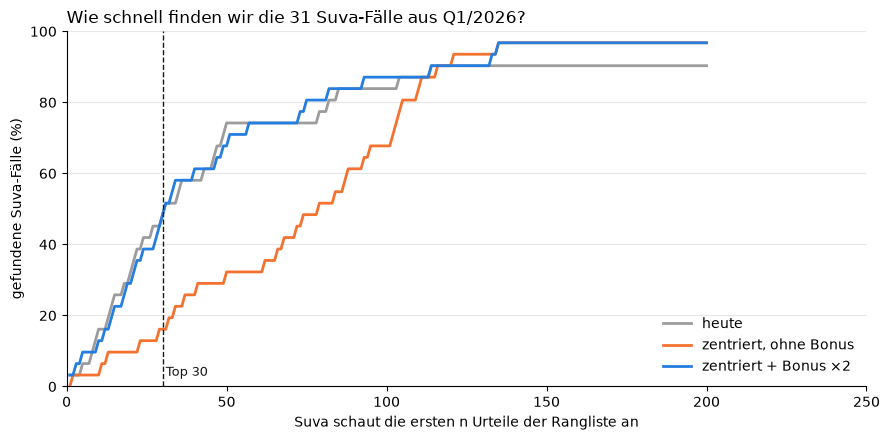

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
show = {"A · Abi: Ähnlichkeit + Bonus (heute)": (GRAY, "heute"),
        "C · zentriert: nur Ähnlichkeit": (ORANGE, "zentriert, ohne Bonus"),
        list(variants)[-1]: (BLUE, f"zentriert + Bonus ×{BONUS:g}")}
for name, (color, label) in show.items():
    curve = recall_curve(variants[name], 200)
    ax.plot(curve.index, curve.values * 100, color=color, linewidth=2, label=label)
ax.legend(frameon=False, loc="lower right")
ax.axvline(30, color=INK, linewidth=1, linestyle="--")
ax.text(31, 3, "Top 30", fontsize=9, color=INK)
ax.set_xlabel("Suva schaut die ersten n Urteile der Rangliste an")
ax.set_ylabel("gefundene Suva-Fälle (%)")
ax.set_ylim(0, 100)
ax.set_xlim(0, 250)
ax.grid(axis="y", color="#e6e6e6")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Wie schnell finden wir die 31 Suva-Fälle aus Q1/2026?", loc="left")
fig.tight_layout()
plt.show()

## 5. Passen die ähnlichen Referenzfälle besser?

Für jedes Urteil zeigt die UI die ähnlichsten Suva-Fälle („similar cases“). Prüfung: Gehört der **ähnlichste Referenzfall zum gleichen Rechtsgebiet**
(Unfall, Invalidität, Kranken, Arbeitslosen)? Gezählt werden nur Urteile aus der Sozialversicherung.


In [8]:
def same_area(frame, only_suva):
    f = frame[frame.is_reference] if only_suva else frame
    f = f[f.subject.map(subject_area) != "andere"]
    return np.mean([subject_area(s) == subject_area(t[0]) for s, t in zip(f.subject, f.top_refs_subjects)]) if len(f) else np.nan

for f in (raw_sim, cen_sim):
    f["top_refs_subjects"] = f["top_ref_subjects"]
pd.DataFrame({
    "heute (roh)": {"Suva-Fälle": same_area(raw_sim, True), "alle Sozialversicherungs-Urteile": same_area(raw_sim, False)},
    "zentriert": {"Suva-Fälle": same_area(cen_sim, True), "alle Sozialversicherungs-Urteile": same_area(cen_sim, False)},
}).map("{:.0%}".format)

,heute (roh),zentriert
Suva-Fälle,97%,97%
alle Sozialversicherungs-Urteile,63%,63%


In [9]:
example = cen_sim[cen_sim.is_reference].iloc[0]
print(f"Beispiel {example.case_id}: {example.subject}")
for variant, frame in [("heute", raw_sim), ("zentriert", cen_sim)]:
    row = frame.set_index("doc_key").loc[example.doc_key]
    print(f"  {variant:10s} nächste Referenzen:", "; ".join(f"{c} ({s[:35]})" for c, s in zip(row.top_refs, row.top_ref_subjects)))

Beispiel 8C_464/2025: Unfallversicherung (Invalidenrente; Einkommensvergleich)
  heute      nächste Referenzen: 8C_656/2024 (Unfallversicherung); 8C_681/2024 (Unfallversicherung (Berufskrankheit); 8C_719/2024 (Unfallversicherung (Invaliditätsbem)
  zentriert  nächste Referenzen: 8C_656/2024 (Unfallversicherung); 8C_719/2024 (Unfallversicherung (Invaliditätsbem); 8C_681/2024 (Unfallversicherung (Berufskrankheit)


## 6. Was ein Boost- oder Buff-Klick bewirkt

Ein Klick in der UI soll die Pipeline lernen lassen: **Boost** macht das Urteil zur Suva-Referenz, **Buff** zur Negativ-Referenz.
Simuliert ohne Änderung an der Datenbank (`extra_positive` / `extra_negative`). Änderungen in Punkten der Ähnlichkeit ×100.
Eingestellt ist der Klick auf ein Urteil aus Q4/2025, gemessen wird die Wirkung auf alle 2004 Urteile aus Q1/2026 (Referenzen = alle Suva-Fälle vor 2026).


In [10]:
Q1_ALL = dict(date_from="2026-01-01", date_to="2026-03-31")
q4 = corpus.meta[(corpus.meta.decision_date >= "2025-10-01") & (corpus.meta.decision_date <= "2025-12-31")]

# Buff: das am höchsten bewertete Q4-Urteil, das Suva NICHT zusammengefasst hat (typischer Fehlalarm)
q4_scores = score_period(corpus, centre=False, date_from="2025-10-01", date_to="2025-12-31")
buff_key = q4_scores[~q4_scores.is_reference].iloc[0].doc_key
# Boost: das am höchsten bewertete 9C-Urteil (Invalidenversicherung) aus Q4, das noch keine Referenz ist
boost_key = q4_scores[~q4_scores.is_reference & q4_scores.case_id.str.startswith("9C_")].iloc[0].doc_key
print("Buff-Klick auf ", corpus.meta.at[buff_key, "case_id"], "–", corpus.meta.at[buff_key, "subject"])
print("Boost-Klick auf", corpus.meta.at[boost_key, "case_id"], "–", corpus.meta.at[boost_key, "subject"])

def click_effect(centre, bonus, **click):
    before = score_period(corpus, centre=centre, bonus_scale=bonus, **Q1_ALL).set_index("doc_key")
    after = score_period(corpus, centre=centre, bonus_scale=bonus, **Q1_ALL, **click).set_index("doc_key")
    delta = after.score - before.score
    same = before.subject.map(subject_area) == subject_area(corpus.meta.at[click_key(click), "subject"])
    return {"Ø Änderung gleiches Rechtsgebiet": delta[same].mean(), "Ø Änderung übrige Urteile": delta[~same].mean(),
            "Urteile mit > 1 Punkt Änderung": int((delta.abs() > 1).sum()),
            "Suva-Fälle über alter F2-Schwelle (vorher → nachher)": threshold_hits(before, after)}

def click_key(click):
    return (click.get("extra_negative") or click.get("extra_positive"))[0]

def threshold_hits(before, after):
    thr = to_scored_cases_best(before)
    return f"{int((before.is_reference & (before.score >= thr)).sum())} → {int((after.is_reference & (after.score >= thr)).sum())}"

def to_scored_cases_best(frame):
    from hack_apertus_coffee_exe.eval.eval import evaluate
    return evaluate("", to_scored_cases(frame.reset_index())).best["threshold"]

clicks = pd.DataFrame({
    "Buff · heute": click_effect(False, 1.0, extra_negative=(buff_key,)),
    f"Buff · zentriert + Bonus ×{BONUS:g}": click_effect(True, BONUS, extra_negative=(buff_key,)),
    "Boost · heute": click_effect(False, 1.0, extra_positive=(boost_key,)),
    f"Boost · zentriert + Bonus ×{BONUS:g}": click_effect(True, BONUS, extra_positive=(boost_key,)),
}).T
clicks

Buff-Klick auf  8C_221/2025 – Assurance-accidents (indemnité pour atteinte à l'intégrité)
Boost-Klick auf 9C_406/2025 – Assicurazione per l'invalidità (rendita d'invalidità)


,Ø Änderung gleiches Rechtsgebiet,Ø Änderung übrige Urteile,Urteile mit > 1 Punkt Änderung,Suva-Fälle über alter F2-Schwelle (vorher → nachher)
Buff · heute,-27.52,-26.823,2004,23 → 0
Buff · zentriert + Bonus ×2,-9.319,-4.185,1232,22 → 12
Boost · heute,0.06,0.059,82,23 → 23
Boost · zentriert + Bonus ×2,0.5,0.586,104,22 → 22


**Lesart:** Ein guter Klick verschiebt vor allem Urteile aus **dem gleichen Rechtsgebiet** und lässt die übrigen in Ruhe.
Heute zieht ein einziger Buff **alle** Urteile gleich stark nach unten, weil sich mit e5 alle Urteile zu etwa 0.95 ähneln. Danach liegt kein Suva-Fall mehr über der Schwelle.


## 7. Fazit und Empfehlung

| Frage | Antwort |
|---|---|
| Trennt die **Ähnlichkeit** besser? | **Ja.** Abstand Unfall↔Unfall vs. Unfall↔fachfremd 0.02 → 0.28, Trennschärfe d' 2.3 → 3.0, Scores über 70 statt 11 Punkte verteilt. |
| Wird die **Rangliste / Evaluation** besser? | **Nein, praktisch gleich.** Fair gewählt (Bonus ×2 auf Q4): F2 0.635 statt 0.661, Recall@30 gleich (48 %), Recall@100 87 % statt 84 % (= 1 Fall). Bei 31 Suva-Fällen ist 1 Fall schon 3 Prozentpunkte, das ist Rauschen. |
| Passen die **ähnlichen Referenzfälle** besser? | **Gleich gut.** Für Suva-Fälle ist der nächste Referenzfall schon heute zu 97 % aus dem gleichen Rechtsgebiet. |
| Wirkt **Buff** sinnvoll? | **Heute nein:** ein Klick zieht alle 2004 Urteile um etwa 27 Punkte runter, danach liegt kein Suva-Fall mehr über der Schwelle. **Zentriert besser, aber nicht gut:** das gleiche Rechtsgebiet sinkt doppelt so stark wie der Rest, trotzdem fällt die Hälfte der Suva-Fälle unter die Schwelle. |
| Wirkt **Boost** sinnvoll? | **Nein, in beiden Varianten kaum** (< 1 Punkt): Eine zusätzliche Referenz neben 59 bestehenden fällt bei „Mittel der 3 ähnlichsten“ nicht ins Gewicht. |

**Warum wird die Rangliste nicht besser, obwohl die Ähnlichkeit besser trennt?** Die schwierigen Fälle sind nicht Unfall vs. Strafrecht, das schafft auch der Bonus.
Schwierig ist: **Welche der rund 100 Unfall-Urteile fasst Suva zusammen?** Dafür sind sich diese Urteile auch zentriert zu ähnlich.
Das ist eine inhaltliche Frage (neue Rechtsfrage, Praxisänderung?), die ein Ähnlichkeitsmass nicht beantworten kann.

**Empfehlung**
1. **Score für die Rangliste bleibt Abis Version.** Zentrieren lohnt sich für die Rangliste nicht, es ändert nichts Messbares.
2. **Feedback-Klicks nicht über „Klick = Referenz“ lernen lassen,** so wie `score_candidates` heute rechnet: Buff macht die Scores kaputt, Boost wirkt nicht.
   - Sofort-Effekt: Der Klick verschiebt nur dieses Urteil über bzw. unter die Relevanz-Schwelle.
   - Lerneffekt: separat bauen und messen, z. B. Abzug nur, wenn ein Urteil der Negativ-Referenz *ähnlicher* ist als den Suva-Referenzen, auf zentrierten Vektoren.
3. **Der grösste Hebel ist die Reihenfolge innerhalb der Unfall-Urteile.** Das ist die Aufgabe von Apertus (`final_score` in der Triage), nicht der Embeddings.

**Grenzen:** ein Testquartal mit 31 Suva-Fällen, Bonus-Faktor auf einem Quartal mit nur 23 Referenzen gewählt, nur ein Boost- und ein Buff-Beispiel simuliert.
